# Literal four-spin Lindblad workload

This fixed study uses **n=4, r=211, local Z0 and all 15,756 complete trials** with $t=1$, $J=0.6$, $h_x=0.35$, rates 0.8/0.5/0.5/0.5 and +i/+/+/+ input. Every trial retains 1,481 source resets, all Hamiltonian/damping components and eight final system/environment readouts. The full four-system output remains correlated; the score depends only on the first logical bit. The repeated trial population and hardware schedule are unexecuted. Numerical checks of the complete source, routed and Clifford+T trials have completed.

This notebook loads the saved source/routed/Clifford+T records and physical statuses, verifies their identities, and runs **one fresh full eight-wire density source check** plus independent gate-derived and GKSL references. It starts no native synthesis or QDK estimate. Prepared or physical failures remain explicit; a missing point is not zero qubits or zero time. All earlier n2/n3 bundles and historical negative n4 APIs remain preserved.


In [1]:
from pathlib import Path
from fractions import Fraction
from dataclasses import asdict
from collections import Counter
import hashlib, importlib.metadata, json, math, platform, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display
from qiskit import qasm3

root=Path.cwd()
local=(root/"lindblad_four_physical.py").is_file()
if not local and root.name=="notebooks" and (root.parent/"src/openquantum/simulation/lindblad_four_physical.py").is_file():
    root=root.parent
if not local and (root/"src/openquantum/simulation/lindblad_four_physical.py").is_file():
    sys.path.insert(0,str(root/"src"))
    from openquantum.simulation import lindblad_four_physical as lp
    from openquantum.simulation import lindblad_four_density as di
    from openquantum.simulation import lindblad_four_compile as cc
    from openquantum.simulation import bounded_density_instrument as legacy_di
    from openquantum.simulation import lindblad_workload as lw
    from openquantum import instrument_resources as ir
    asset_dir=root/"assets/generated/simulation/lindblad-four"
else:
    sys.path.insert(0,str(root))
    import lindblad_four_physical as lp
    import lindblad_four_density as di
    import lindblad_four_compile as cc
    import bounded_density_instrument as legacy_di
    import lindblad_workload as lw
    import instrument_resources as ir
    asset_dir=root
get_ipython().run_line_magic("matplotlib","inline")
manifest=json.loads((asset_dir/"manifest.json").read_text())
results=json.loads((asset_dir/"results.json").read_text())
recorded_python=manifest.get("python")
if recorded_python is not None:
    assert platform.python_version()==recorded_python, "Use the recorded locked Python runtime."
else:
    assert platform.python_version()=="3.12.14", "Use the supplied locked Python3.12.14 runtime."
    print("Original failed-attempt Python version was not recorded; this fresh source kernel observes",platform.python_version())
preflight=results["source_preflight"]
assert preflight is not None, "This notebook requires the completed bounded source-preflight evidence."
prepared=results.get("prepared")
science=prepared if prepared is not None else preflight
profiles=results["physical_profiles"]
assert len(profiles) in (0,2)
assert {r["profile"]["physical_error_rate"] for r in profiles}==({1e-3,1e-4} if profiles else set())
if not profiles:
    assert prepared is None and results.get("full_clifford_t_trial_completed") is False
    print("Failed capsule contains no completed physical-profile reports.")
family=results["family"]
family_records=list(family.values()) if isinstance(family,dict) else family
for name,expected in manifest["artifacts_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for name,expected in manifest["source_sha256"].items():
    assert hashlib.sha256((asset_dir/name).read_bytes()).hexdigest()==expected, name
for module in (lp,di,cc,legacy_di,lw,ir):
    path=Path(module.__file__)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==manifest["source_sha256"][path.name], path.name
recorded_packages=manifest.get("packages")
if recorded_packages is None:
    pins={}
    for line in (asset_dir/"requirements-lock.txt").read_text().splitlines():
        match=re.match(r"^([A-Za-z0-9_.-]+)==([^;\s]+)",line.strip())
        if match:
            pins[match.group(1).lower()]=match.group(2)
    recorded_packages={name:pins[name] for name in ("qiskit","qdk","numpy","scipy","matplotlib")}
    print("Original failed-attempt package versions were not recorded; current fresh imports are checked against the copied lock.")
for name,expected in recorded_packages.items():
    assert importlib.metadata.version(name)==expected, name
allocations=results.get("family_allocations",science["family_allocations"])
checker_limits=di.EightWireDensityLimits(**science["checker_limits"])
assert checker_limits.max_qubits==8 and checker_limits.source_operations==20000
assert checker_limits.validation_operations==2000000 and checker_limits.matrix_cache_bytes==1024**2
assert legacy_di.DenseInstrumentLimits().max_qubits==5
assert legacy_di.DenseInstrumentLimits().source_operations==10000
assert legacy_di.DenseInstrumentLimits().validation_operations==100000
assert legacy_di.MAX_DENSITY_QUBITS==6
assert ir.InstrumentLimits().synthesized_operations==100000
try:
    ir.InstrumentLimits(synthesized_operations=2000000)
except ValueError:
    pass
else:
    raise AssertionError("The frozen shared one-million hard ceiling must remain unchanged.")
materialization_limits=cc.FourCompilerLimits(**science["materialization_limits"])
assert asdict(materialization_limits)=={"max_qubits":8,"source_operations":20000,"routed_operations":100000,"synthesized_operations":2000000}
assert not isinstance(materialization_limits,ir.InstrumentLimits)
assert preflight["actual_routing"]["compiler_domain"]=="literal-n4-explicit-opt-in-v1"
assert preflight["actual_routing"]["materialization_limits"]==asdict(materialization_limits)
def table(frame):
    def formatted(value):
        return f"{value:.9g}" if isinstance(value,(float,np.floating)) else str(value)
    display(frame.style.hide(axis="index").format(formatted,na_rep="—"))
def fraction(record):
    return Fraction(record["numerator"],record["denominator"])
def density(record):
    return np.array(record["real"])+1j*np.array(record["imag"])
def point(report):
    values=report.get("pareto_points",[])
    return min(values,key=lambda p:(p["peak_physical_qubits"],p["worst_case_runtime_all_attempts_ns"])) if values else None
print("Saved hashes, imported source files and locked packages verified.")
execution=results.get("execution",{})
stage_status=execution.get("stage_status",{})
print("Preparation/attempt status:",stage_status.get("prepare",{}).get("status",results.get("status","not recorded")))


Saved hashes, imported source files and locked packages verified.
Preparation/attempt status: completed


## Full correlated source and independent references

The explicit checker propagates the full $256\times256$ density operator, summing both reset Kraus terms without recording histories. Before the first system readout it retains the full $16\times16$ system state and all 16 probabilities in logical c3c2c1c0 order. Ignored measurements dephase. A classical product of marginals is never substituted for the interacting state.

The state/trace guard $10^{-8}$ and source/routing equivalence guard $10^{-10}$ were declared before the compiled result. The checker reports raw trace and divides the captured reduced state by its trace once at output. With no acceptance condition this is numerical normalization, not algorithm postselection. It certifies no representation, compiler or hardware norm.


stage,Z0
GKSL reference,0.791050758
Fresh literal source,0.791051439
Saved routed,0.791051439
Saved actual Clifford+T,0.791051346


comparison,trace_norm
Source vs gate-derived state,1.02841644e-13
Source vs full GKSL state,6.66373253e-06
Raw trace drift before output,2.93098879e-14


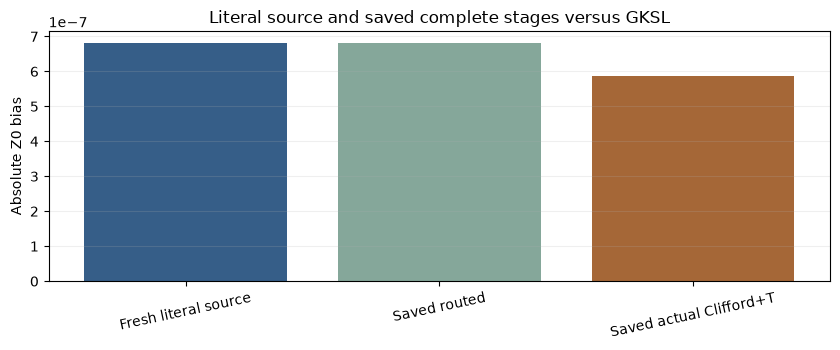

In [2]:
task=lp.source_task()
assert asdict(task)=={"n_system":4,"time":1.0,"J":0.6,"hx":0.35,"rate0":0.8,"other_rate":0.5}
assert lw.select_steps(task)==211 and lw.output_contract()["complete_trials_per_case"]==15756
source=lp.build_source(task)
di.validate_density_source(source,limits=checker_limits)
assert source.num_qubits==source.num_clbits==8 and len(source.data)==9934
assert source.count_ops()["reset"]==1481 and source.count_ops()["measure"]==8
source_readouts=[(source.find_bit(item.clbits[0]).index,source.find_bit(item.qubits[0]).index)
                 for item in source.data if item.operation.name=="measure"]
assert source_readouts==[(q,q) for q in range(8)]
qasm_hashes=dict(preflight["qasm_sha256"])
if prepared is not None:
    qasm_hashes.update(prepared["qasm_sha256"])
assert hashlib.sha256(qasm3.dumps(source).encode()).hexdigest()==qasm_hashes["source-trial.qasm"]
saved_checks={"source-trial.qasm":science["source_instrument_check"],
              "routed-rotation-trial.qasm":science["routed_instrument_check"]}
if prepared is not None:
    saved_checks["clifford-t-trial.qasm"]=prepared["clifford_t_instrument_check"]
for name,expected in qasm_hashes.items():
    raw=(asset_dir/name).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==expected, name
    readouts=re.findall(r"^\s*c\[(\d+)\]\s*=\s*measure\s+(?:q\[(\d+)\]|\$(\d+));\s*$",raw.decode(),re.MULTILINE)
    assert len(readouts)==8, name
    assert [int(bit) for bit,_,_ in readouts]==list(range(8)), name
    mapping={int(bit):int(register_wire or physical_wire) for bit,register_wire,physical_wire in readouts}
    assert set(mapping)==set(mapping.values())==set(range(8)), name
    assert [mapping[q] for q in range(4)]==saved_checks[name]["outcome_wires"], name
fresh=di.simulate_density_trial(source,(0,1,2,3),lp.score_values(),{},limits=checker_limits)
rho=fresh["reduced_before_output"]
reference=lw.reference_density(task)
gate_reference=lw.gate_density(task,211)
observable=lw.on_wire(lw.Z,0,4)
exact=float(np.trace(observable@reference).real)
guard=1e-10
state_guard=1e-8
assert rho.shape==(16,16) and fresh["joint_probabilities"].shape==(16,)
assert abs(fresh["unnormalized_trace_before_output"]-1)<state_guard
assert fresh["normalization_divisor"]==fresh["unnormalized_trace_before_output"]
assert fresh["normalization_is_postselection"] is False
assert abs(np.trace(rho)-1)<guard and np.linalg.eigvalsh(rho).min()>-guard
assert np.linalg.norm(rho-gate_reference,ord="nuc")<guard
assert np.linalg.norm(rho-reference,ord="nuc")<=float(lw.uniform_split_bound(task,211))+guard
saved_source=science["source_instrument_check"]
assert abs(fresh["mean"]-saved_source["mean"])<guard
assert np.linalg.norm(rho-density(saved_source["reduced_before_output"]),ord="nuc")<guard
assert np.max(np.abs(fresh["joint_probabilities"]-saved_source["joint_probabilities"]))<guard
assert abs(float(np.trace(observable@gate_reference).real)-fresh["mean"])<guard
assert abs(exact-science["independent_reference"]["exact_GKSL_Z0"])<guard
sim=fresh["simulation"]
assert sim["density_shape"]==[256,256] and sim["density_state_bytes"]==1048576
assert sim["reset_history_measured_outputs"] is False
assert sim["reset_history_classical_bits_created"]==0 and sim["trajectory_branch_pruning"] is False
assert sim["explicit_instrument_counts"]=={"reset":1481,"measure":8}
assert sim["peak_matrix_cache_bytes"]<=sim["matrix_cache_bytes_limit"]==1024**2
assert sim["index_group_cache_bytes"]<=128*1024 and sim["hard_classical_bit_cap"]==16
answers=[{"stage":"GKSL reference","Z0":exact},
         {"stage":"Fresh literal source","Z0":fresh["mean"]},
         {"stage":"Saved routed","Z0":science["routed_instrument_check"]["mean"]}]
if prepared is not None:
    answers.append({"stage":"Saved actual Clifford+T","Z0":prepared["clifford_t_instrument_check"]["mean"]})
table(pd.DataFrame(answers))
table(pd.DataFrame([{"comparison":"Source vs gate-derived state","trace_norm":np.linalg.norm(rho-gate_reference,ord="nuc")},
                    {"comparison":"Source vs full GKSL state","trace_norm":np.linalg.norm(rho-reference,ord="nuc")},
                    {"comparison":"Raw trace drift before output","trace_norm":abs(fresh["unnormalized_trace_before_output"]-1)}]))
fig,ax=plt.subplots(figsize=(8.5,3.6))
ax.bar([r["stage"] for r in answers[1:]],[abs(r["Z0"]-exact) for r in answers[1:]],color=["#365e88","#85a79a","#a56737"][:len(answers)-1])
ax.set(ylabel="Absolute Z0 bias",title="Literal source and saved complete stages versus GKSL")
ax.ticklabel_format(axis="y",style="sci",scilimits=(-3,3))
ax.tick_params(axis="x",rotation=12)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()


## Correlations, raw trace and normalized output

A product of four single-system marginals preserves the local Z0 mean but generally changes the selected joint state, ZZ witnesses and all 16 probabilities. This is a classical diagnostic only. It is no replacement quantum circuit or pruning rule.

The saved raw trace and once-at-output numerical divisor remain visible alongside the full normalized system density. The comparison with actual Clifford+T is made only when that complete prepared stage exists.


stage,raw_trace,raw_trace_drift,normalized_trace
Source,1,2.67563749e-14,1
Routed,1,1.96065386e-13,1
Actual Clifford+T,1,1.72785786e-10,1


observable,literal_source,product_of_source_marginals,GKSL_reference
Z0,0.791051439,0.791051439,0.791050758
Z0 Z1,0.43959675,0.3675331,0.439597705
Z1 Z2,0.422641551,0.195783616,0.422642876
Z2 Z3,0.43936007,0.170716175,0.439361607


Product-marginal selected-state trace-norm discrepancy: 0.9479594925546209


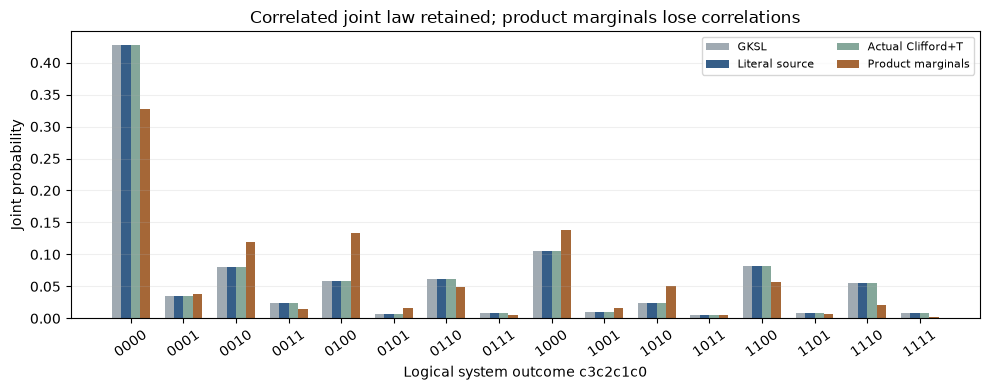

In [3]:
def local_marginal(state,q):
    result=np.zeros((2,2),dtype=complex)
    rest=[j for j in range(4) if j!=q]
    for a in range(2):
        for b in range(2):
            for x in range(8):
                offset=sum(((x>>k)&1)<<j for k,j in enumerate(rest))
                result[a,b]+=state[offset|(a<<q),offset|(b<<q)]
    return result
marginals=[local_marginal(rho,q) for q in range(4)]
product=np.array([[1+0j]])
for q in reversed(range(4)):
    product=np.kron(product,marginals[q])
assert abs(np.trace(observable@product).real-fresh["mean"])<guard
assert np.linalg.norm(rho-product,ord="nuc")>.5
routed=science["routed_instrument_check"]
routed_rho=density(routed["reduced_before_output"])
assert np.linalg.norm(rho-routed_rho,ord="nuc")<guard
assert np.max(np.abs(fresh["joint_probabilities"]-routed["joint_probabilities"]))<guard
checks=[("Source",saved_source),("Routed",routed)]
actual=None
if prepared is not None:
    actual=prepared["clifford_t_instrument_check"]
    actual_rho=density(actual["reduced_before_output"])
    realization=prepared["error_contract"]["realization_Z0_bias_upper_proposal"]
    assert np.linalg.norm(rho-actual_rho,ord="nuc")<=realization+guard
    assert np.sum(np.abs(fresh["joint_probabilities"]-actual["joint_probabilities"]))<=realization+guard
    checks.append(("Actual Clifford+T",actual))
trace_rows=[]
for label,check in checks:
    state=density(check["reduced_before_output"])
    assert check["outcome_clbits"]==[0,1,2,3]
    assert len(check["outcome_wires"])==len(set(check["outcome_wires"]))==4
    assert all(0<=q<8 for q in check["outcome_wires"])
    assert check["score_values"]==list(lp.score_values())
    assert len(check["joint_probabilities"])==16
    assert np.max(np.abs(np.diag(state).real-check["joint_probabilities"]))<guard
    assert abs(sum(check["joint_probabilities"])-1)<guard
    assert abs(np.dot(lp.score_values(),check["joint_probabilities"])-check["mean"])<guard
    assert check["simulation"]["trajectory_branch_pruning"] is False
    assert check["simulation"]["reset_history_measured_outputs"] is False
    assert check["normalization_is_postselection"] is False
    raw_trace=check["unnormalized_trace_before_output"]
    assert abs(raw_trace-1)<state_guard
    assert check["normalization_divisor"]==raw_trace
    trace_rows.append({"stage":label,"raw_trace":raw_trace,"raw_trace_drift":abs(raw_trace-1),"normalized_trace":float(np.trace(state).real)})
table(pd.DataFrame(trace_rows))
witnesses={"Z0":observable}
for q in range(3):
    witnesses[f"Z{q} Z{q+1}"]=lw.on_wire(lw.Z,q,4)@lw.on_wire(lw.Z,q+1,4)
table(pd.DataFrame([{"observable":name,"literal_source":float(np.trace(op@rho).real),
                    "product_of_source_marginals":float(np.trace(op@product).real),
                    "GKSL_reference":float(np.trace(op@reference).real)} for name,op in witnesses.items()]))
print("Product-marginal selected-state trace-norm discrepancy:",np.linalg.norm(rho-product,ord="nuc"))
fig,ax=plt.subplots(figsize=(10,4))
x=np.arange(16)
laws=[(-.27,np.diag(reference).real,"GKSL","#a0aab2"),
      (-.09,fresh["joint_probabilities"],"Literal source","#365e88"),
      (.27,np.diag(product).real,"Product marginals","#a56737")]
if actual is not None:
    laws.insert(2,(.09,actual["joint_probabilities"],"Actual Clifford+T","#85a79a"))
for offset,law,label,color in laws:
    ax.bar(x+offset,law,width=.18,label=label,color=color)
ax.set(xticks=x,xticklabels=[f"{i:04b}" for i in range(16)],xlabel="Logical system outcome c3c2c1c0",ylabel="Joint probability",title="Correlated joint law retained; product marginals lose correlations")
ax.tick_params(axis="x",rotation=35)
ax.legend(fontsize=8,ncol=2)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()


## Complete source, compiled gates and all trials

Every trial keeps all 422/422/422/211 environment reset events and eight final readouts, with eight source first-wire resets and 1,473 reuse resets. The frozen geometry adds 23 workspace/bridge startups, giving 31 startup patches per trial.

Source and routed counts are executed preflight evidence. Clifford+T counts are used only when the entire emitted trial passed its two-million guard and correlated checks. Cached native targets never remove repeated quantum occurrences. The following all-trial populations are calculated, unexecuted multiplications.


primitive,per_complete_trial,all_15756_trials
h,661278,10419096168
t,642284,10119826704
s,349839,5512063284
cx,14130,222632280
x,5908,93086448
reset,1481,23334636
measure,8,126048


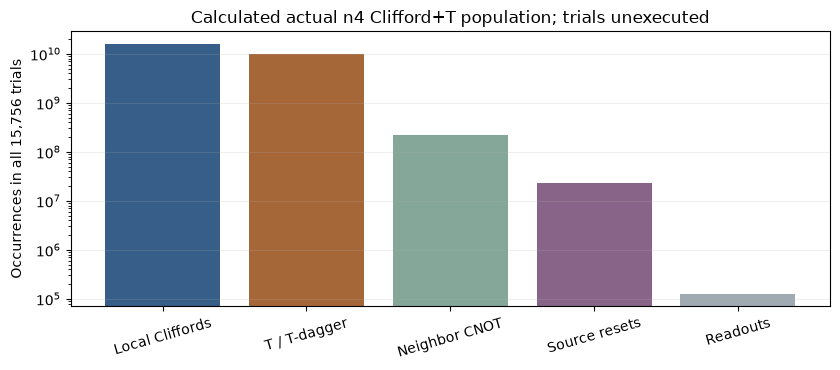

In [4]:
source_counts=dict(source.count_ops())
assert source_counts=={"cx":4009,"rx":1688,"reset":1481,"cry":1477,"rz":1266,"measure":8,"h":4,"s":1}
routed_counts=preflight["actual_routing"]["routed_counts"]
assert routed_counts["cx"]==14130 and routed_counts["barrier"]==2978
assert sum(routed_counts.values())==24510
counts=source_counts
synthesis=None
w=None
if prepared is not None:
    w=prepared["complete_workload"]
    counts=w["primitive_counts_per_complete_trial"]
    synthesis=prepared["actual_synthesis"]
    assert w["complete_trials"]==w["complete_attempts"]==15756
    assert w["algorithm_retry_cap"]==1 and w["postselection"]=="none"
    assert w["whole_workload_executed"] is False
    assert w["reset_per_trial"]==counts["reset"]==1481
    assert w["readout_per_trial"]==counts["measure"]==8
    assert w["source_resets_all_trials"]==23334636 and w["source_readouts_all_trials"]==126048
    assert w["environment_initializations_per_trial"]==[422,422,422,211]
    assert w["discard_resets_before_environment_reuse_per_trial"]==[421,421,421,210]
    assert w["source_first_wire_initializations_per_trial"]==8 and w["source_reuse_resets_per_trial"]==1473
    assert w["workspace_startup_initializations_per_trial"]==23 and w["reserved_logical_patches"]==31
    assert w["workspace_startup_initializations_all_trials"]==362388
    assert w["logical_startup_initializations_all_trials"]==488436
    assert w["data_output_clbits"]==[0,1,2,3] and w["ignored_environment_readout_clbits"]==[4,5,6,7]
    assert w["unobserved_reset_histories_claimed_as_outputs"] is False
    assert synthesis["rotation_occurrences"]==5908
    assert synthesis["routed_counts"]==routed_counts
    assert synthesis["clifford_t_counts"]["reset"]==1481 and synthesis["clifford_t_counts"]["measure"]==8
    assert sum(synthesis["clifford_t_counts"].values())<=2000000
    assert set(counts)<=ir.CLIFFORD_T|{"reset","measure"}
    for name,count in counts.items():
        assert w["primitive_counts_all_trials"][name]==count*15756
        assert synthesis["clifford_t_counts"][name]==count
table(pd.DataFrame([{"primitive":name,"per_complete_trial":count,"all_15756_trials":count*15756} for name,count in counts.items()]))
if prepared is not None:
    groups={"Local Cliffords":sum(counts.get(g,0) for g in ("h","x","y","z","s","sdg")),
            "T / T-dagger":sum(counts.get(g,0) for g in ("t","tdg")),
            "Neighbor CNOT":counts.get("cx",0),"Source resets":counts["reset"],"Readouts":counts["measure"]}
    title="Calculated actual n4 Clifford+T population; trials unexecuted"
else:
    groups={"Source RX/RZ/CRY":sum(counts.get(g,0) for g in ("rx","rz","cry")),
            "Source CNOT":counts["cx"],"Source resets":counts["reset"],"Readouts":counts["measure"]}
    title="Calculated source population; complete Clifford+T unavailable"
fig,ax=plt.subplots(figsize=(8.5,3.8))
ax.bar(groups.keys(),[v*15756 for v in groups.values()],color=["#365e88","#a56737","#85a79a","#876488","#a0aab2"][:len(groups)])
ax.set(yscale="log",ylabel="Occurrences in all 15,756 trials",title=title)
ax.tick_params(axis="x",rotation=16)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()


## Unchanged physical assumptions and explicit statuses

Both profiles retain physical error $10^{-3}$ or $10^{-4}$ and controller failure $10^{-15}$ per decision. Gates/initialization take 100 ns, measurement 500 ns, cycles 1,000 ns and controller reaction 10,000 ns. Geometry, memory, encoder, readout and factory-interface assumptions remain frozen.

The actual T/T-dagger wire distribution determines controller work and the minimal complete factory retry cap for every required magic state across all trials. A controller-only rejection leaves other fault components, factory searches and space/time unevaluated. Such a rejection concerns the additive engineering model, not an observed hardware failure lower bound. No point or improved controller scenario is invented.


physical_error,required_magic_states,minimal_full_retry_cap,capped_pipeline_attempts,readiness_union_bound,controller_decisions_per_trial
0.001,10119826704,7,70838786928,0.000101198267,123409809


physical_error,required_magic_states,minimal_full_retry_cap,capped_pipeline_attempts,readiness_union_bound,controller_decisions_per_trial
0.0001,10119826704,7,70838786928,0.000101198267,123409809


physical_error,status,distance,peak_physical_qubits,all_trial_hours,controller_model_contribution,physical_fault_model,allocated_physical_budget,Pareto_points
0.001,infeasible_declared_controller_model,—,—,—,0.00194444495,—,0.000833333333,0
0.0001,infeasible_declared_controller_model,—,—,—,0.00194444495,—,0.000833333333,0


planned_api,planned_block_generator,controller_decisions_before,controller_decisions_required_at_most,minimum_required_reduction,proposal_executed,physical_feasibility_claimed
estimate_verified_four,port_verified_rotation_blocks_to_zero,123409809,52889904,70519905,False,False


planned_api,planned_block_generator,controller_decisions_before,controller_decisions_required_at_most,minimum_required_reduction,proposal_executed,physical_feasibility_claimed
estimate_verified_four,port_verified_rotation_blocks_to_zero,123409809,52889904,70519905,False,False


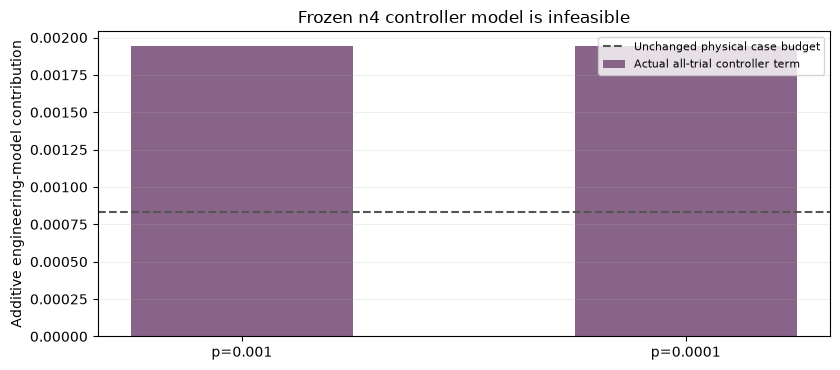

In [5]:
ct_counts=None
t_wires=Counter()
first_resets=reuse_resets=0
if prepared is not None:
    text=(asset_dir/"clifford-t-trial.qasm").read_text()
    assert not re.search(r"^\s*gate\s",text,re.MULTILINE), "This pinned CT export must contain only explicit standard primitives."
    ct_counts=Counter()
    active=set()
    output_started=False
    for line in text.splitlines():
        line=line.strip()
        measured=re.fullmatch(r"c\[(\d+)\]\s*=\s*measure\s+(?:q\[(\d+)\]|\$(\d+));",line)
        if measured:
            wire=int(measured.group(2) or measured.group(3))
            assert wire in active
            ct_counts["measure"]+=1
            output_started=True
            continue
        gate=re.match(r"^(h|x|y|z|s|sdg|t|tdg|cx|reset|barrier)\s+(.+);$",line)
        if not gate:
            continue
        name,arguments=gate.groups()
        wires=[int(q or physical) for q,physical in re.findall(r"q\[(\d+)\]|\$(\d+)",arguments)]
        ct_counts[name]+=1
        if name=="barrier":
            continue
        assert not output_started, "No quantum work may follow the first final readout."
        if name=="reset":
            assert len(wires)==1
            if wires[0] not in active:
                first_resets+=1
            else:
                reuse_resets+=1
            active.add(wires[0])
        else:
            assert set(wires)<=active
            if name=="cx":
                assert len(wires)==2 and abs(wires[0]-wires[1])==1
            if name in ("t","tdg"):
                assert len(wires)==1
                t_wires[(name,wires[0])]+=1
    assert dict(ct_counts)==synthesis["clifford_t_counts"]
    assert first_resets==8 and reuse_resets==1473 and ct_counts["measure"]==8
rows=[]
for report,frozen in zip(profiles,lp.fixed_profiles()):
    assert report["profile"]==asdict(frozen)
    assert report["profile"]["controller_failure_per_decision"]==1e-15
    assert report["complete_algorithm_attempts"]==15756
    allocation=allocations["case_allocations"]["4"]
    physical_budget=report.get("physical_failure_budget",allocation["physical_failure_budget"])
    readiness_budget_float=report.get("factory_availability_budget",allocation["factory_availability_budget"])
    assert Fraction.from_float(physical_budget)<=Fraction(1,1200)
    assert Fraction.from_float(readiness_budget_float)<=Fraction(1,1200)
    best=point(report)
    diagnostic=report.get("controller_model_diagnostic",{})
    if diagnostic:
        assert prepared is not None
        states=(ct_counts.get("t",0)+ct_counts.get("tdg",0))*15756
        readiness_budget=Fraction.from_float(readiness_budget_float)
        retry=next(k for k in range(1,17) if states*Fraction(1,100)**k<=readiness_budget)
        assert retry==diagnostic["factory_retry_cap"]
        decisions=(first_resets+23)+5*reuse_resets+3*ct_counts["measure"]+1
        decisions+=11*ct_counts["cx"]+sum(ct_counts.get(g,0) for g in ("h","x","y","z","s","sdg"))
        decisions+=sum(number*(47+33*wire+4*retry+(name=="tdg")) for (name,wire),number in t_wires.items())
        assert decisions==diagnostic["controller_decisions_per_trial"]
        assert diagnostic["controller_decisions_all_trials"]==decisions*15756
        assert math.isclose(diagnostic["distance_independent_controller_model_contribution"],decisions*15756*1e-15,rel_tol=1e-14)
        table(pd.DataFrame([{"physical_error":report["profile"]["physical_error_rate"],"required_magic_states":states,"minimal_full_retry_cap":retry,"capped_pipeline_attempts":states*retry,"readiness_union_bound":float(states*Fraction(1,100)**retry),"controller_decisions_per_trial":decisions}]))
    if best:
        assert report["status"]=="computed_conditional_instrument_surface_code_model"
        for value in report["all_feasible_points"]:
            components=value["failure_components_all_attempts"]
            supply=value["factory_supply"]
            assert math.isclose(sum(components.values()),value["full_physical_failure_model"],rel_tol=1e-10,abs_tol=1e-13)
            assert value["full_physical_failure_model"]<=physical_budget
            assert supply["availability_failure_union_bound"]<=readiness_budget_float
            assert value["reserved_logical_patches"]==31
            assert value["data_workspace_physical_qubits"]==31*(2*value["data_code_distance"]**2-1)
            assert value["peak_physical_qubits"]==value["data_workspace_physical_qubits"]+value["factory_physical_qubits"]
            assert value["worst_case_runtime_all_attempts_ns"]==value["runtime_per_complete_attempt_ns"]*15756
            assert sum(row["count"]*row["time_ns"] for row in value["macro_ledger_per_complete_attempt"])==value["runtime_per_complete_attempt_ns"]
            assert supply["states_all_complete_attempts"]==states
            assert supply["worst_case_pipeline_attempts"]==states*supply["full_pipeline_retry_cap_per_state"]
        assert diagnostic["budget_exceeded"] is False
    if report["status"]=="infeasible_declared_controller_model":
        assert diagnostic["budget_exceeded"] is True
        assert diagnostic["distance_independent_controller_model_contribution"]>physical_budget
        assert decisions>52889904
        assert not report["pareto_points"] and not report["all_feasible_points"]
    rows.append({"physical_error":report["profile"]["physical_error_rate"],"status":report["status"],
                 "distance":best["data_code_distance"] if best else None,
                 "peak_physical_qubits":best["peak_physical_qubits"] if best else None,
                 "all_trial_hours":best["worst_case_runtime_all_attempts_ns"]/3.6e12 if best else None,
                 "controller_model_contribution":diagnostic.get("distance_independent_controller_model_contribution"),
                 "physical_fault_model":best["full_physical_failure_model"] if best else None,
                 "allocated_physical_budget":physical_budget,"Pareto_points":len(report.get("pareto_points",[]))})
if not rows:
    rows=[{"physical_error":profile.physical_error_rate,
           "status":"No recorded physical result in failed capsule",
           "distance":None,"peak_physical_qubits":None,"all_trial_hours":None,
           "allocated_physical_budget":allocations["case_allocations"]["4"]["physical_failure_budget"]}
          for profile in lp.fixed_profiles()]
table(pd.DataFrame(rows))
for report in profiles:
    proposal=report.get("matched_task_implementation_proposal")
    if proposal:
        assert proposal["proposed_implementation_executed"] is False
        assert proposal["feasibility_claimed"] is False and proposal["task_changed"] is False
        assert proposal["accuracy_allocations_hardware_geometry_controller_changed"] is False
        recipe=proposal["primary_block_porting_recipe"]
        assert recipe["implementation_executed"] is False and recipe["feasibility_guaranteed"] is False
        assert recipe["free_initialization_or_quantum_occurrence_pruning"] is False
        assert recipe["native_synthesis_attempts_if_verified_blocks_reused"]==0
        assert recipe["extra_neighbor_CX_per_rewritten_block"].startswith("6*w")
        assert recipe["operation_limits"]["ported_clifford_t_and_validation"]==2000000
        assert proposal["controller_decisions_per_trial_before"]==report["controller_model_diagnostic"]["controller_decisions_per_trial"]
        assert proposal["controller_decisions_per_trial_required_at_most"]==report["controller_model_diagnostic"]["maximum_allowed_controller_decisions_per_trial"]
        table(pd.DataFrame([{"planned_api":proposal["native_validation_adapter"]["planned_api"],
                            "planned_block_generator":recipe["planned_generator_api"],
                            "controller_decisions_before":proposal["controller_decisions_per_trial_before"],
                            "controller_decisions_required_at_most":proposal["controller_decisions_per_trial_required_at_most"],
                            "minimum_required_reduction":proposal["controller_decisions_per_trial_reduction_required_at_least"],
                            "proposal_executed":proposal["proposed_implementation_executed"],
                            "physical_feasibility_claimed":proposal["feasibility_claimed"]}]))
fig,ax=plt.subplots(figsize=(8.5,3.8))
if any(point(report) for report in profiles):
    for report,color in zip(profiles,("#365e88","#a56737")):
        points=report.get("pareto_points",[])
        if points:
            ax.plot([p["peak_physical_qubits"] for p in points],[p["worst_case_runtime_all_attempts_ns"]/3.6e12 for p in points],"o-",color=color,label=f"p={report['profile']['physical_error_rate']:g}")
    ax.set(xscale="log",yscale="log",xlabel="Peak physical qubits",ylabel="All-trial hours",title="Conditional frontier for the same n4 task")
    ax.legend(fontsize=8)
elif profiles and all(report.get("controller_model_diagnostic") for report in profiles):
    values=[report["controller_model_diagnostic"]["distance_independent_controller_model_contribution"] for report in profiles]
    ax.bar(["p=0.001","p=0.0001"],values,color="#876488",width=.5,label="Actual all-trial controller term")
    ax.axhline(float(Fraction(1,1200)),color="#555555",linestyle="--",label="Unchanged physical case budget")
    title="Frozen n4 controller model is infeasible" if all(r["status"]=="infeasible_declared_controller_model" for r in profiles) else "Controller diagnostic only; no complete physical point"
    ax.set(ylabel="Additive engineering-model contribution",title=title)
    ax.legend(fontsize=8)
else:
    statuses="\n".join(f"p={r['profile']['physical_error_rate']:g}: {r['status']}" for r in profiles) or results.get("status","No physical result recorded")
    ax.text(.5,.5,"Physical work remains incomplete\n\n"+statuses,ha="center",va="center",transform=ax.transAxes)
    ax.set(xticks=[],yticks=[],title="Explicit failed or unsupported stages; no space/time point")
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
plt.show()


## Accuracy, failure allocation and certificate scope

The same allowances are retained: 0.01 splitting, 0.01 realization and 0.03 statistics. The three-case family shares remain $1/600$ statistics and separate $1/1200$ physical and readiness allowances for each case. No n2/n3 share is reassigned. The requested native synthesis is $5\times10^{-5}$, with separate $10^{-7}$ representation and SDK/control/routing premises.

When preparation completes, the actual guarded synthesis sum enters conditional premise $\eta$ and the unconditional score-bias proposal $2\eta$. A missing native result shows only the declared realization allowance, not a validated cost/error formula. Numerical density agreement proves neither reserve nor a uniform compiler bound; deterministic bias does not multiply by the trial count.


guarded_synthesis_error,representation_reserve,SDK_reserve,aggregate_absolute_error_proposal
8.76937334e-06,1e-07,1e-07,0.0399832735


stage,absolute_Z0_error
Uniform splitting bound,0.00996533471
Conditional realization proposal,1.79387467e-05
Statistics allowance,0.03


systems,steps,complete_trials,status,physical_status
2,69,15756,preserved_prior_n2_result,prior_result_preserved
3,134,15756,preserved_prior_n3_result,prior_result_preserved
4,211,15756,ensemble_branch_cap_exceeded,infeasible_declared_controller_model


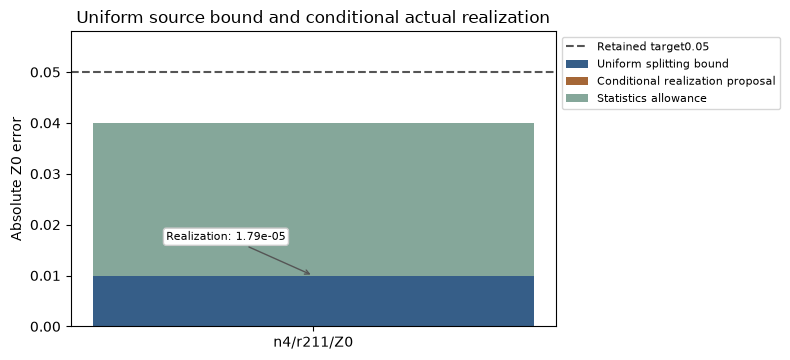

In [6]:
allocations=results.get("family_allocations",science["family_allocations"])
assert allocations["declared_family"]==[2,3,4]
assert allocations["unused_cases_reallocated"] is False and allocations["family_physical_confidence_implemented"] is False
assert fraction(allocations["statistics_family_failure_exact"])==Fraction(1,200)
assert fraction(allocations["physical_family_failure_exact"])==Fraction(1,400)
assert fraction(allocations["factory_family_failure_exact"])==Fraction(1,400)
assert fraction(allocations["total_conditional_family_failure_exact"])==Fraction(1,100)
for allocation in allocations["case_allocations"].values():
    assert fraction(allocation["statistical_failure_exact"])==Fraction(1,600)
    assert fraction(allocation["physical_failure_exact"])==Fraction(1,1200)
    assert fraction(allocation["factory_availability_failure_exact"])==Fraction(1,1200)
    assert Fraction.from_float(allocation["physical_failure_budget"])<=Fraction(1,1200)
    assert Fraction.from_float(allocation["factory_availability_budget"])<=Fraction(1,1200)
splitting=float(lw.uniform_split_bound(task,211))
assert lw.uniform_split_bound(task,211)==Fraction(1331,133563)
assert lw.uniform_split_bound(task,210)>Fraction(1,100)
if prepared is not None:
    c=prepared["error_contract"]
    representation=prepared["representation_check"]
    assert fraction(c["splitting_bias_exact"])==lw.uniform_split_bound(task,211)
    assert fraction(c["whole_realization_error_exact"])*2<=Fraction(1,100)
    assert c["absolute_Z0_error_upper_proposal"]<=.05
    assert c["splitting_bias_allowance"]==c["realization_bias_allowance"]==.01
    assert c["statistical_absolute_error"]==.03 and c["target_absolute_error"]==.05
    assert c["requested_synthesis_allowance"]==synthesis["operator_error_allowance"]==5e-5
    assert c["representation_norm_reserve_scenario"]==c["SDK_control_routing_norm_reserve_scenario"]==1e-7
    assert c["guarded_actual_synthesis_error"]==synthesis["guarded_numerical_operator_error_upper_estimate"]
    assert c["reserve_is_inferred_from_density_agreement"] is False and c["coherent_error_is_stochastic_failure"] is False
    assert c["full_representation_certificate"] is False and c["formal_synthesis_certificate"] is False and c["hardware_confidence_certificate"] is False
    assert representation["representation_reserve_is_certified"] is False
    assert w["deterministic_bias_multiplied_by_trials"] is False
    budget=[{"stage":"Uniform splitting bound","absolute_Z0_error":c["splitting_bias_upper"]},
            {"stage":"Conditional realization proposal","absolute_Z0_error":c["realization_Z0_bias_upper_proposal"]},
            {"stage":"Statistics allowance","absolute_Z0_error":c["statistical_absolute_error"]}]
    table(pd.DataFrame([{"guarded_synthesis_error":c["guarded_actual_synthesis_error"],"representation_reserve":c["representation_norm_reserve_scenario"],"SDK_reserve":c["SDK_control_routing_norm_reserve_scenario"],"aggregate_absolute_error_proposal":c["absolute_Z0_error_upper_proposal"]}]))
    title="Uniform source bound and conditional actual realization"
else:
    budget=[{"stage":"Uniform source splitting bound","absolute_Z0_error":splitting},
            {"stage":"Declared realization allowance (unverified)","absolute_Z0_error":.01},
            {"stage":"Statistics allowance","absolute_Z0_error":.03}]
    title="Declared budget; complete realized synthesis unavailable"
table(pd.DataFrame(budget))
table(pd.DataFrame([{"systems":r["n_system"],"steps":r["selected_steps"],"complete_trials":r["complete_trials"],"status":r["status"],"physical_status":(", ".join(dict.fromkeys(p["status"] for p in profiles)) if r["n_system"]==4 else r.get("physical_status",r["status"]))} for r in family_records]))
fig,ax=plt.subplots(figsize=(8,3.7))
bottom=0
for row,color in zip(budget,("#365e88","#a56737","#85a79a")):
    ax.bar(["n4/r211/Z0"],[row["absolute_Z0_error"]],bottom=bottom,label=row["stage"],color=color,width=.45)
    bottom+=row["absolute_Z0_error"]
ax.axhline(.05,color="#555555",linestyle="--",label="Retained target0.05")
if prepared is not None:
    ax.annotate(f"Realization: {c['realization_Z0_bias_upper_proposal']:.3g}",
                xy=(0,c["splitting_bias_upper"]+c["realization_Z0_bias_upper_proposal"]/2),xytext=(-.15,.017),
                arrowprops={"arrowstyle":"->","color":"#555555"},bbox={"boxstyle":"round,pad=.25","fc":"white","ec":"#cccccc"},fontsize=8)
ax.set(ylabel="Absolute Z0 error",ylim=(0,.058),title=title)
ax.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1,1))
fig.tight_layout()
plt.show()


## Reproduction, provenance and retained negative domains

Generate the new bundle using the recorded Python 3.12 lock and the separate generator. This notebook requires its completed source-preflight evidence and copied modules; it verifies loaded native records and executes only the source check. In a downloaded directory, place the Python modules, manifest/results/inventory/CSV, QASMs, lock, license and references beside this notebook. Git, a GPU and native synthesis are unnecessary for its source check.

The earlier five-wire defaults, six-wire density hard ceiling and one-million shared materialization guard remain unchanged. The new named APIs require explicit 8/20k/2m limits. Historical ensemble rejection and any actual one-million guard rejection retain their own scope; a post-generation guard check is not an executed legacy synthesis attempt. All originals stay intact and the inventory measures local logical bytes, not public hosting occupancy.

Saved QASM and sequence hashes identify native synthesis; its backend exposes no seed API. Compiler seed7 is fixed. Measured-instrument QASM omits overall phase and is not a controlled-oracle specification. Coherent unitary-segment reuse requires its phase convention and recorded phase. Offline preprocessing/report time, layout certification, decoder throughput and hardware calibration retain separate scope. Full-family physical confidence and any matched co-design improvement remain unimplemented.


In [7]:
if "frozen_before" in manifest:
    assert manifest["frozen_before"]==manifest["frozen_after"]
    assert manifest["whole_family_physical_completed"] is False
    assert manifest["synthesis_seed"] is None and manifest["transpiler_seed"]==7
else:
    assert prepared is None and manifest["full_clifford_t_trial_completed"] is False
    assert manifest["physical_results_completed"] is False
    print("Original failed-attempt seed/revision/frozen metadata were not recorded; no native or hardware result is inferred.")
assert manifest["private_cache_distributed"] is False
caps=manifest["run_caps"]
assert caps["physical_cases"]==caps["prepared_synthesis_stages"]==1 and caps["physical_profiles"]==2
assert caps["density_wires"]==8 and caps["density_matrix_bytes"]==1048576
assert caps["native_rotation_synthesis_attempts_upper_bound"]==23632
assert caps["factory_queries_per_profile"]==caps["surface_code_queries_per_profile"]==24
assert caps["factory_candidates_per_query"]==1000 and caps["factory_candidates_per_profile"]==24000
assert caps["managed_json_qasm_bytes"]==32*1024**2 and caps["private_checkpoint_bytes"]==256*1024**2
assert caps["prepare_seconds"]==1800 and caps["parent_seconds"]==2400
if prepared is not None:
    assert prepared["hardware_execution"] is False and prepared["formal_confidence_certificate"] is False
    assert prepared["joint_system_correlations_preserved"] is True
    assert prepared["unobserved_reset_histories_are_measured_outputs"] is False
    assert synthesis["actual_synthesis_sequences_generated"] is True
    assert synthesis["preserve_full_unitary"] is True and synthesis["transpiler_qubits_initially_zero"] is False
    assert synthesis["formal_interval_certificate"] is False
    assert 0<synthesis["native_rotation_synthesis_attempts"]<=23632
    print("Observed native attempts:",synthesis["native_rotation_synthesis_attempts"])
    print("Actual unique targets:",synthesis["unique_rotation_targets"])
phases=dict(preflight["qasm_export"]["in_memory_global_phase_radians"])
if prepared is not None:
    phases.update(prepared["qasm_export"]["in_memory_global_phase_radians"])
    assert phases["clifford-t-trial.qasm"]==synthesis["compiled_global_phase"]
    assert "limits" not in synthesis
    assert synthesis["compiler_domain"]=="literal-n4-explicit-opt-in-v1"
    assert synthesis["materialization_limits"]==asdict(materialization_limits)
    assert synthesis["native_synthesis_backend"]["qiskit_262_cargo_lock_version"]=="0.2.2"
    assert synthesis["native_synthesis_backend"]["upstream_tag_commit"]=="0e94e5638c42624f4ec358f5eab079942462d2bf"
    legacy_materialization=prepared["legacy_materialization_validation"]
    assert legacy_materialization["legacy_operation_cap"]==1000000
    assert legacy_materialization["actual_operations"]==sum(synthesis["clifford_t_counts"].values())
    assert legacy_materialization["legacy_synthesis_performed"] is False
    assert legacy_materialization["legacy_physical_estimation_performed"] is False
    if legacy_materialization["actual_operations"]>1000000:
        assert legacy_materialization["status"]=="rejected_actual_clifford_t_operations"
        assert legacy_materialization["rejection_reproduced"] is True
    else:
        assert legacy_materialization["status"]=="passed_frozen_operation_guard"
assert set(phases)==set(qasm_hashes) and all(math.isfinite(v) for v in phases.values())
historical_n4=next((record for record in family_records if record["n_system"]==4),None)
if historical_n4 is not None:
    assert historical_n4["density_checker_status"]=="density_width_cap_exceeded"
    assert historical_n4["density_required_wires"]==8 and historical_n4["density_supported_wires"]==6
    assert historical_n4["density_width_rejection_reproduced"] is True
    assert historical_n4["limits"]["validation_branches"]==256
    assert historical_n4["legacy_synthesis_performed"] is False
    assert historical_n4["legacy_physical_estimation_performed"] is False
    assert historical_n4["family_allocation_reallocated"] is False
    if stage_status.get("family",{}).get("status")=="completed":
        assert historical_n4["status"]=="ensemble_branch_cap_exceeded"
        assert historical_n4["rejection_reproduced"] is True and "branch cap" in historical_n4["reason"]
    else:
        print("Current complete family diagnostic status was not recorded; the retained historical status is",historical_n4["status"])
else:
    print("No historical family diagnostic was retained in this failed capsule.")
legacy_bounds=legacy_di.DenseInstrumentLimits(max_qubits=6,source_operations=20000,validation_operations=1000000)
try:
    legacy_di.validate_density_source(source,limits=legacy_bounds)
except ValueError as error:
    assert "width" in str(error)
else:
    raise AssertionError("The historical six-wire density cap must still reject this source.")
for record in family_records:
    if record["n_system"] in (2,3):
        assert record["regenerated"] is False
        assert record["source_or_synthesis_rerun"] is False
table(pd.DataFrame([{"cap":name.replace("_"," "),"value":value} for name,value in caps.items() if isinstance(value,int) and not isinstance(value,bool)]))
inventory=pd.read_csv(asset_dir/"artifact-inventory.csv")
inventory_record=json.loads((asset_dir/"artifact-inventory.json").read_text())
assert len(inventory)==inventory_record["payload_files"]==manifest["artifact_inventory"]["payload_files"]
assert int(inventory["bytes"].sum())==inventory_record["payload_bytes"]==manifest["artifact_inventory"]["payload_bytes"]
assert inventory_record["originals_preserved"] is True
for row in inventory.to_dict("records"):
    raw=(asset_dir/row["file"]).read_bytes()
    assert len(raw)==row["bytes"] and hashlib.sha256(raw).hexdigest()==row["sha256"], row["file"]
table(inventory.groupby("category",sort=False).agg(files=("file","count"),bytes=("bytes","sum")).reset_index())
print("Managed local payload:",inventory_record["payload_files"],"files;",inventory_record["payload_bytes"],"bytes. Recursive metadata is separate; this is not public hosting occupancy.")
print("Source/correlations, complete readouts, budgets, loaded status records and preserved old domains verified.")


Observed native attempts: 8
Actual unique targets: 8


cap,value
physical cases,1
prepared synthesis stages,1
native rotation synthesis attempts upper bound,23632
physical profiles,2
source instructions,20000
routed instructions,100000
synthesized instructions,2000000
routed and synthesized instructions,2000000
density validation instructions,2000000
density wires,8


category,files,bytes
copied_license_or_primary_references,2,12000
result_or_documentation,5,367011
copied_frozen_source_dependency,5,132815
actual_circuit_export,3,14362207
original_figure,5,256932
new_original_source_snapshot,4,168435
copied_environment_lock,1,1974


Managed local payload: 25 files; 15301374 bytes. Recursive metadata is separate; this is not public hosting occupancy.
Source/correlations, complete readouts, budgets, loaded status records and preserved old domains verified.
